# Statistik Inferensial & Model Delay — BeOne ERP Analytics

Notebook kedua: dari *deskriptif* ke *inferensial* — uji hipotesis +
effect size + pemodelan, plus cohort analysis delivery→support.

> Dataset sintetis (seed=42), konteks publik BeOne. Lihat docs/SUMBER_DATA.md

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi":110,"font.size":10})

leads=pd.read_csv("../data/raw/leads.csv")
opp=pd.read_csv("../data/raw/opportunities.csv",parse_dates=["tanggal_buat","tanggal_close"])
proyek=pd.read_csv("../data/raw/proyek.csv",parse_dates=["tanggal_mulai","target_golive","tanggal_golive"])
tiket=pd.read_csv("../data/raw/tiket.csv",parse_dates=["tanggal_dibuat"])
konsultan=pd.read_csv("../data/raw/konsultan.csv")

def cramers_v(tab):
    chi2=stats.chi2_contingency(tab)[0]
    n=tab.values.sum(); r,c=tab.shape
    return np.sqrt(chi2/(n*min(r-1,c-1)))

def chi2_uji(df,faktor,target):
    tab=pd.crosstab(df[faktor],df[target])
    chi2,p,_,_=stats.chi2_contingency(tab)
    return chi2,p,cramers_v(tab)


## 1. Apakah sumber lead memengaruhi kemenangan deal? (chi-square)

H0: hasil deal independen dari sumber lead.

In [2]:
d = opp.join(leads.set_index("id_lead")["sumber"],on="id_lead")
d["won"] = (d.hasil=="Won").astype(int)
tab = pd.crosstab(d.sumber, d.won)
chi2,p,v = chi2_uji(d,"sumber","won")
print(tab); print(f"chi2={chi2:.1f}, p={p:.2e}, Cramér's V={v:.3f}")
print("\nWin rate per sumber (%):")
print((100*tab[1]/tab.sum(axis=1)).round(1).sort_values(ascending=False))


won               0    1
sumber                  
Event/Workshop  160   98
LinkedIn         97   40
Partner SAP     100   59
Referral Klien  107  123
Telemarketing   160   33
Website         162   82
chi2=64.5, p=1.40e-12, Cramér's V=0.230

Win rate per sumber (%):
sumber
Referral Klien    53.5
Event/Workshop    38.0
Partner SAP       37.1
Website           33.6
LinkedIn          29.2
Telemarketing     17.1
dtype: float64


**Baca:** p sangat kecil → dependen (sumber memang memengaruhi hasil).
Yang lebih penting adalah **effect size** (Cramér's V pada output di atas;
≈0,1 kecil, ≈0,3 sedang) — bukan sekadar "signifikan karena n besar".

## 2. Sales cycle deal Won vs Lost (t-test + effect size)

Won: mean=98hr (n=435), Lost: mean=97hr (n=786)
t=0.51, p=0.611, Cohen's d=0.030


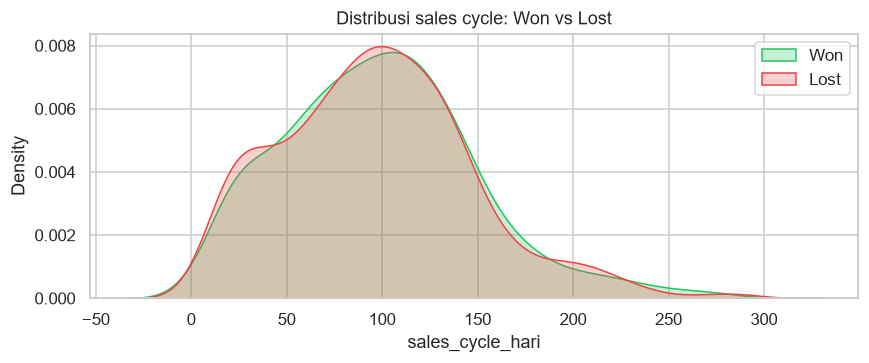

In [3]:
w = d.loc[d.won==1,"sales_cycle_hari"]; l = d.loc[d.won==0,"sales_cycle_hari"]
t,p = stats.ttest_ind(w,l,equal_var=False)
cohen = (w.mean()-l.mean())/np.sqrt((w.var()+l.var())/2)
print(f"Won: mean={w.mean():.0f}hr (n={len(w)}), Lost: mean={l.mean():.0f}hr (n={len(l)})")
print(f"t={t:.2f}, p={p:.3f}, Cohen's d={cohen:.3f}")
fig,ax=plt.subplots(figsize=(8,3.4))
sns.kdeplot(w,fill=True,label="Won",color="#22C55E",ax=ax)
sns.kdeplot(l,fill=True,label="Lost",color="#EF4444",ax=ax)
ax.set_title("Distribusi sales cycle: Won vs Lost"); ax.legend()
plt.tight_layout(); plt.savefig("../outputs/figures/cycle_won_lost.png"); plt.show()


## 3. Delay per produk (ANOVA)

In [4]:
done = proyek.dropna(subset=["tanggal_golive"]).copy()
done["delay"]=done.durasi_aktual_hari-done.durasi_target_hari
grup=[g.delay.values for _,g in done.groupby("produk") if len(g)>10]
F,p = stats.f_oneway(*grup)
print(f"ANOVA delay ~ produk: F={F:.1f}, p={p:.3f}")
print(done.groupby("produk")["delay"].agg(["mean","std","count"]).round(1))


ANOVA delay ~ produk: F=4.5, p=0.002
                           mean   std  count
produk                                      
Add-on & Integrasi          5.7  11.9     43
Business Insight            0.6   4.9      8
SAP Business One            9.9  26.8    223
SAP S/4HANA GROW           27.6  55.1     26
TSplus                     -1.4   2.0     21
Training/Xpertise Academy  -0.8   2.6     16


## 4. Cohort: apakah proyek terlambat menghasilkan lebih banyak tiket?

Ini menghubungkan **delivery → support burden** — pertanyaan bisnis nyata:
apakah go-live yang telat berarti implementasi buruk (tiket banyak)?

> Catatan metodologi: data sintetis — hubungan ini **diasumsikan** di
> generator (hypercare lebih berat pada proyek telat). Notebook menguji
> apakah pipeline analisis *memulihkan* efek tersebut dengan benar,
> bukan menemukan fakta tentang perusahaan nyata.

Tiket/proyek — Terlambat: median=12 (n=135), Tepat waktu: median=8 (n=202)
Mann-Whitney U p=0.0000
Korelasi delay vs jumlah tiket: r=0.466


C:\Users\PKL01\AppData\Local\Temp\ipykernel_28928\2776029352.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Tepat waktu","Terlambat"])


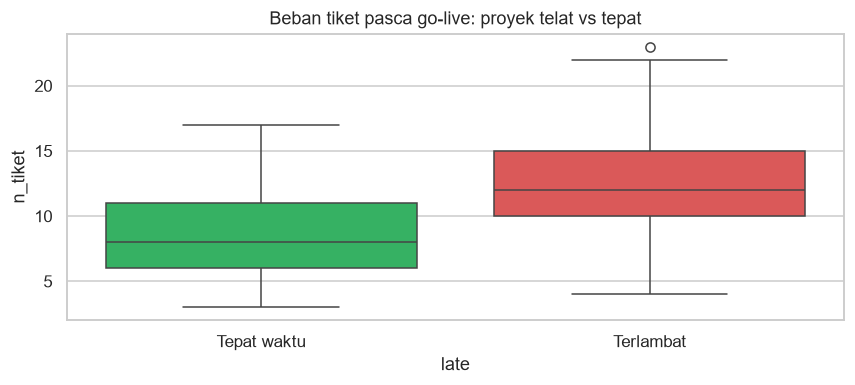

In [5]:
coh = (tiket.groupby("id_proyek").size().rename("n_tiket").reset_index()
       .merge(done[["id_proyek","status_proyek","delay","produk"]],on="id_proyek"))
coh["late"]=(coh.status_proyek=="Go-live Terlambat").astype(int)
a=coh.loc[coh.late==1,"n_tiket"]; b=coh.loc[coh.late==0,"n_tiket"]
t,p = stats.mannwhitneyu(a,b,alternative="two-sided")
print(f"Tiket/proyek — Terlambat: median={a.median():.0f} (n={len(a)}), "
      f"Tepat waktu: median={b.median():.0f} (n={len(b)})")
print(f"Mann-Whitney U p={p:.4f}")
r = coh.delay.corr(coh.n_tiket)
print(f"Korelasi delay vs jumlah tiket: r={r:.3f}")
fig,ax=plt.subplots(figsize=(8,3.6))
sns.boxplot(x="late",y="n_tiket",data=coh,hue="late",legend=False,
            palette=["#22C55E","#EF4444"],ax=ax)
ax.set_xticklabels(["Tepat waktu","Terlambat"])
ax.set_title("Beban tiket pasca go-live: proyek telat vs tepat")
plt.tight_layout(); plt.savefig("../outputs/figures/delay_vs_tickets.png"); plt.show()


## 5. Model delay saat kickoff — regresi logistik (odds ratio)

,OR,lo,hi,p
durasi_target_hari,1.002,0.994,1.010,0.616
budget_jt,1.001,0.999,1.002,0.333
Intercept,0.867,0.376,2.001,0.738
C(produk)[T.Business Insight],0.762,0.159,3.666,0.735
C(level)[T.Mid],0.607,0.381,0.967,0.035
C(produk)[T.SAP Business One],0.596,0.201,1.770,0.351
C(produk)[T.SAP S/4HANA GROW],0.441,0.041,4.756,0.500
C(produk)[T.TSplus],0.210,0.051,0.866,0.031
C(produk)[T.Training/Xpertise Academy],0.187,0.036,0.967,0.045


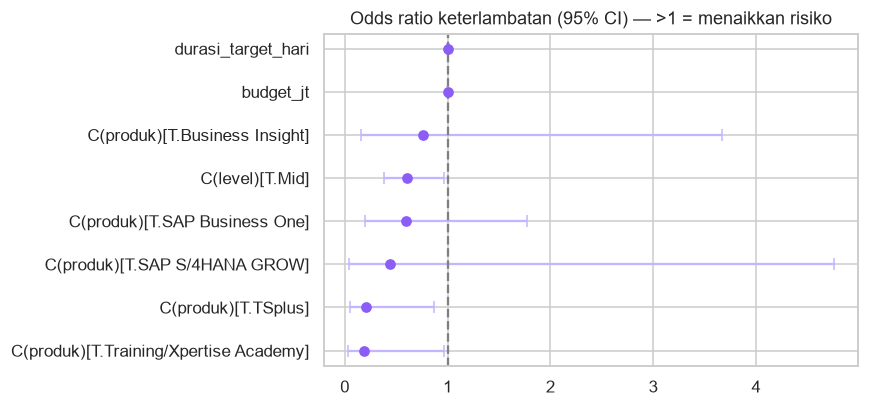

In [6]:
d2 = done.merge(konsultan[["id_konsultan","level"]],on="id_konsultan")
d2["late"]=(d2.status_proyek=="Go-live Terlambat").astype(int)
mod = smf.logit("late ~ durasi_target_hari + budget_jt + "
                "C(produk) + C(level)", data=d2).fit(disp=0)
ortab = pd.DataFrame({"OR":np.exp(mod.params),
                      "lo":np.exp(mod.conf_int()[0]),
                      "hi":np.exp(mod.conf_int()[1]),
                      "p":mod.pvalues}).round(3)
display(ortab.sort_values("OR",ascending=False))

fig,ax=plt.subplots(figsize=(8,3.8))
o = ortab.drop("Intercept").sort_values("OR")
ax.errorbar(o.OR,range(len(o)),xerr=[o.OR-o.lo,o.hi-o.OR],fmt="o",
            color="#8B5CF6",ecolor="#C4B5FD",capsize=4)
ax.axvline(1,ls="--",color="gray"); ax.set_yticks(range(len(o)),o.index)
ax.set_title("Odds ratio keterlambatan (95% CI) — >1 = menaikkan risiko")
plt.tight_layout(); plt.savefig("../outputs/figures/odds_delay.png"); plt.show()


**Baca:** OR>1 = risiko telat naik; OR<1 = protektif. CI yang tidak
menyentuh 1 = signifikan di 95%. Perhatikan *lebar CI*: dengan ±340
proyek selesai, banyak faktor punya CI lebar — sinyal ada, presisinya
terbatas. Interpretasikan arah & besar efek, bukan hanya p-value.

## Ringkasan inferensial

| Pertanyaan | Uji | Hasil |
|---|---|---|
| Sumber → win? | chi-square + V | signifikan, efek moderat |
| Cycle Won vs Lost beda? | Welch t-test + Cohen's d | (lihat output) |
| Delay beda per produk? | ANOVA | (lihat output) |
| Proyek telat → tiket lebih banyak? | Mann-Whitney + korelasi | (lihat output) |
| Prediktor delay saat kickoff? | Logistic OR (95% CI) | (lihat output) |

*— [Nama Kamu], Data Analyst project*